# 🦟 Dengue Alerta — Painel Epidemiológico de Monitoramento de Risco
**Fontes:** SINAN (notificações) + INMET (clima semanal)

Fluxo do notebook:
1. Imports e parâmetros
2. Carrega os dados
3. Mapeamento automático de colunas
4. Pré-processamento do SINAN
5. Pré-processamento do INMET e cruzamento
6. Detecção de anomalias (média móvel + k desvios)
7. Curvas: casos reais × limiar esperado
8. Clima × casos (gráficos comparativos e correlação defasada)
9. Índice de risco por localidade
10. Mapa interativo de risco
11. Alerta de Tendência automatizado

## Célula 1 — Imports e parâmetros

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

# ----------------------------- PARÂMETROS DO MODELO -----------------------------
JANELA = 8                    # semanas da média móvel (linha de base "esperada")
N_DESVIOS = 2.0               # limiar = média móvel + N_DESVIOS * desvio móvel
MIN_CASOS = 5                 # só marca anomalia se a semana tiver ao menos X casos
MIN_TOTAL_LOC = 30            # ignora localidades com menos de X casos no período todo
DESCARTAR_ULTIMAS_SEMANAS = 1 # a última semana costuma estar incompleta (atraso de notificação)
LAG_MAX = 8                   # defasagem máxima (semanas) na correlação clima -> casos
SEMANAS_RECENTES = 4          # janela usada no índice de risco e no alerta
COORD_MUN_CSV = None          # opcional: CSV com colunas codigo, lat, lon (município) p/ mapa detalhado

## Célula 2 — Carga dos dados
O notebook procura os arquivos subindo a partir da pasta atual (ignora a `venv`), então funciona de qualquer subpasta do projeto.

In [2]:
PASTAS_IGNORADAS = {"venv", ".venv", ".git", "__pycache__", "node_modules", ".ipynb_checkpoints"}

def achar_arquivo(nome):
    """Procura `nome` a partir da pasta atual e sobe pelos diretórios pais."""
    base = Path.cwd().resolve()
    for pasta in [base, *base.parents]:
        for raiz, dirs, arquivos in os.walk(pasta):
            dirs[:] = [d for d in dirs if d not in PASTAS_IGNORADAS]
            if nome in arquivos:
                return Path(raiz) / nome
    raise FileNotFoundError(f"'{nome}' não encontrado a partir de {Path.cwd()}")

def ler_csv(caminho):
    """Lê CSV detectando separador (; ou ,) e encoding (utf-8 ou latin-1)."""
    for enc in ("utf-8-sig", "latin-1"):
        try:
            with open(caminho, "r", encoding=enc) as f:
                primeira = f.readline()
            sep = ";" if primeira.count(";") > primeira.count(",") else ","
            return pd.read_csv(caminho, sep=sep, encoding=enc, low_memory=False)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Não consegui ler {caminho}")

CAM_SINAN = achar_arquivo("sinan_tratado.csv")
CAM_INMET = achar_arquivo("inmet_semanal_estacoes.csv")
print("SINAN:", CAM_SINAN)
print("INMET:", CAM_INMET)

sinan_raw = ler_csv(CAM_SINAN)
inmet_raw = ler_csv(CAM_INMET)

print(f"\nSINAN: {sinan_raw.shape[0]:,} linhas x {sinan_raw.shape[1]} colunas")
print(f"INMET: {inmet_raw.shape[0]:,} linhas x {inmet_raw.shape[1]} colunas")

print("\n--- Tipos e nulos: SINAN ---")
display(pd.DataFrame({"tipo": sinan_raw.dtypes.astype(str), "nulos": sinan_raw.isna().sum(),
                      "% nulos": sinan_raw.isna().mean() * 100}))
print("\n--- Tipos e nulos: INMET ---")
display(pd.DataFrame({"tipo": inmet_raw.dtypes.astype(str), "nulos": inmet_raw.isna().sum(),
                      "% nulos": inmet_raw.isna().mean() * 100}))
display(sinan_raw.head(3))
display(inmet_raw.head(3))

SINAN: C:\Users\Usuário\Desktop\Dengue_Alerta\data\processed\sinan_tratado.csv
INMET: C:\Users\Usuário\Desktop\Dengue_Alerta\data\processed\inmet_semanal_estacoes.csv

SINAN: 13,778,942 linhas x 6 colunas
INMET: 182,712 linhas x 10 colunas

--- Tipos e nulos: SINAN ---


,tipo,nulos,% nulos
DT_NOTIFIC,str,0,0.00
SEM_NOT,int64,0,0.00
NU_ANO,int64,0,0.00
SG_UF_NOT,int64,0,0.00
ID_MUNICIP,int64,0,0.00
CLASSI_FIN,float64,16444,0.12



--- Tipos e nulos: INMET ---


,tipo,nulos,% nulos
semana,str,0,0.00
chuva_semana_mm,float64,0,0.00
horas_validas,int64,0,0.00
uf,str,0,0.00
estacao,str,0,0.00
codigo,str,0,0.00
lat,float64,0,0.00
lon,float64,0,0.00
nivel_chuva,str,0,0.00
semana_confiavel,bool,0,0.00


,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,CLASSI_FIN
0,2020-01-26,202005,2020,12,120020,5.00
1,2020-01-30,202005,2020,12,120020,5.00
2,2020-02-11,202007,2020,12,120020,5.00


,semana,chuva_semana_mm,horas_validas,uf,estacao,codigo,lat,lon,nivel_chuva,semana_confiavel
0,2019-12-29,51.40,96,DF,BRASILIA,A001,-15.79,-47.93,forte,False
1,2020-01-05,74.20,168,DF,BRASILIA,A001,-15.79,-47.93,forte,True
2,2020-01-12,1.60,168,DF,BRASILIA,A001,-15.79,-47.93,fraca,True


## Célula 3 — Mapeamento de colunas
Os nomes das colunas variam de acordo com o seu tratamento. A célula tenta **detectar automaticamente**; confira o resultado impresso e, se algo estiver errado, preencha `MAPA_MANUAL` com o nome exato da coluna e rode de novo.

In [4]:
MAPA_MANUAL = {   # preencha apenas se a detecção automática errar, ex.: "sinan_municipio": "ID_MUNICIP"
    "sinan_data": None, "sinan_semana": None, "sinan_municipio": None, "sinan_uf": None, "sinan_casos": None,
    "inmet_data": None, "inmet_semana": None, "inmet_uf": None, "inmet_estacao": None,
    "inmet_temp": None, "inmet_precip": None, "inmet_umid": None,
    "inmet_lat": None, "inmet_lon": None,
}

def achar_coluna(df, chave, candidatos):
    """Procura coluna por nome exato e depois por trecho (só p/ candidatos com mais de 3 letras)."""
    if MAPA_MANUAL.get(chave):
        return MAPA_MANUAL[chave]
    norm = {str(c).lower().strip(): c for c in df.columns}
    for cand in candidatos:
        if cand in norm:
            return norm[cand]
    for cand in candidatos:
        if len(cand) > 3:
            for k, c in norm.items():
                if cand in k:
                    return c
    return None

# --- SINAN ---
c_s_data = achar_coluna(sinan_raw, "sinan_data", ["data", "dt_notific", "dt_sin_pri", "data_notificacao",
                                                  "semana_inicio", "inicio_semana", "data_semana", "dt_semana"])
c_s_sem  = achar_coluna(sinan_raw, "sinan_semana", ["sem_not", "sem_pri", "semana_epidemiologica", "semana_epi", "semana", "se"])
c_s_mun  = achar_coluna(sinan_raw, "sinan_municipio", ["id_municip", "id_mn_resi", "municipio", "nm_municipio",
                                                       "cod_municipio", "co_mun", "localidade"])
c_s_uf   = achar_coluna(sinan_raw, "sinan_uf", ["sg_uf_not", "sg_uf", "uf", "id_uf", "sigla_uf"])
c_s_cas  = achar_coluna(sinan_raw, "sinan_casos", ["casos", "n_casos", "num_casos", "total_casos", "notificacoes", "qtd_casos"])

# --- INMET ---
c_i_data = achar_coluna(inmet_raw, "inmet_data", ["data", "data_semana", "semana_inicio", "inicio_semana", "dt_semana", "week_start"])
c_i_sem  = achar_coluna(inmet_raw, "inmet_semana", ["semana", "semana_epidemiologica", "semana_epi", "se"])
c_i_uf   = achar_coluna(inmet_raw, "inmet_uf", ["uf", "sg_uf", "sigla_uf", "estado"])
c_i_est  = achar_coluna(inmet_raw, "inmet_estacao", ["estacao", "nome_estacao", "cd_estacao", "codigo_estacao", "station"])
c_i_lat  = achar_coluna(inmet_raw, "inmet_lat", ["latitude", "lat"])
c_i_lon  = achar_coluna(inmet_raw, "inmet_lon", ["longitude", "lon", "lng"])

def escolher_clima(df, chave, padroes):
    """Escolhe a coluna climática numérica que contém um dos padrões (prefere as que têm 'med')."""
    if MAPA_MANUAL.get(chave):
        return MAPA_MANUAL[chave]
    numericas = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
    achadas = [c for c in numericas if any(p in str(c).lower() for p in padroes)]
    if not achadas:
        return None
    pref = [c for c in achadas if "med" in str(c).lower() or "mean" in str(c).lower()]
    return (pref or achadas)[0]

c_i_temp   = escolher_clima(inmet_raw, "inmet_temp",   ["temp"])
c_i_precip = escolher_clima(inmet_raw, "inmet_precip", ["precip", "chuva"])
c_i_umid   = escolher_clima(inmet_raw, "inmet_umid",   ["umid"])

print("=== COLUNAS DETECTADAS (confira!) ===")
for nome, val in {"SINAN data": c_s_data, "SINAN semana": c_s_sem, "SINAN município": c_s_mun,
                  "SINAN UF": c_s_uf, "SINAN casos": c_s_cas,
                  "INMET data": c_i_data, "INMET semana": c_i_sem, "INMET UF": c_i_uf, "INMET estação": c_i_est,
                  "INMET temperatura": c_i_temp, "INMET precipitação": c_i_precip, "INMET umidade": c_i_umid,
                  "INMET lat": c_i_lat, "INMET lon": c_i_lon}.items():
    print(f"{nome:20s} -> {val}")

assert (c_s_data or c_s_sem), "SINAN: não achei coluna de data/semana. Preencha MAPA_MANUAL."
assert (c_i_data or c_i_sem), "INMET: não achei coluna de data/semana. Preencha MAPA_MANUAL."
assert (c_s_mun or c_s_uf), "SINAN: preciso de município ou UF. Preencha MAPA_MANUAL."
if not c_s_cas:
    print("\nℹ️ SINAN sem coluna de contagem: cada linha será tratada como 1 notificação.")

=== COLUNAS DETECTADAS (confira!) ===
SINAN data           -> DT_NOTIFIC
SINAN semana         -> SEM_NOT
SINAN município      -> ID_MUNICIP
SINAN UF             -> SG_UF_NOT
SINAN casos          -> None
INMET data           -> None
INMET semana         -> semana
INMET UF             -> uf
INMET estação        -> estacao
INMET temperatura    -> None
INMET precipitação   -> chuva_semana_mm
INMET umidade        -> None
INMET lat            -> lat
INMET lon            -> lon

ℹ️ SINAN sem coluna de contagem: cada linha será tratada como 1 notificação.


## Célula 4 — Pré-processamento do SINAN
- Converte datas e cria a **semana** (início na segunda-feira, igual nas duas bases para alinhar o cruzamento).
- Normaliza a UF (aceita sigla, código IBGE de UF ou código de município).
- Agrega casos por localidade × semana e **completa semanas sem registro com 0** (série contínua é essencial para média móvel).

In [5]:
COD_UF = {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO",
          "21": "MA", "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA",
          "31": "MG", "32": "ES", "33": "RJ", "35": "SP", "41": "PR", "42": "SC", "43": "RS",
          "50": "MS", "51": "MT", "52": "GO", "53": "DF"}
# Centroides aproximados das UFs (usados no mapa quando não há coordenadas por município)
UF_COORD = {"RO": (-10.83, -63.34), "AC": (-9.02, -70.81), "AM": (-3.47, -65.10), "RR": (2.05, -61.40),
            "PA": (-3.79, -52.48), "AP": (1.41, -51.77), "TO": (-10.18, -48.33), "MA": (-5.42, -45.44),
            "PI": (-7.72, -42.73), "CE": (-5.20, -39.53), "RN": (-5.81, -36.59), "PB": (-7.12, -36.72),
            "PE": (-8.38, -37.86), "AL": (-9.62, -36.82), "SE": (-10.57, -37.45), "BA": (-12.96, -41.70),
            "MG": (-18.51, -44.55), "ES": (-19.19, -40.34), "RJ": (-22.25, -42.66), "SP": (-22.19, -48.79),
            "PR": (-24.89, -51.55), "SC": (-27.45, -50.22), "RS": (-30.17, -53.50), "MS": (-20.51, -54.54),
            "MT": (-12.64, -55.42), "GO": (-15.98, -49.86), "DF": (-15.83, -47.86)}

def normalizar_uf(serie):
    """Aceita 'PI', '22' ou código de município (ex.: 220010) e devolve a sigla da UF."""
    s = serie.astype(str).str.strip().str.upper().str.replace(r"\.0$", "", regex=True)
    ehnum = s.str.match(r"^\d+$")
    return s.where(~ehnum, s.str[:2].map(COD_UF))

def extrair_semana(df, c_data, c_sem):
    """Devolve a segunda-feira (00:00:00) de início da semana a partir de data ou código AAAASS."""
    col = c_data or c_sem
    ser = df[col]
    txt = ser.astype(str).str.strip().str.replace(r"\.0$", "", regex=True)

    # 1) Se vier no formato numérico compacto AAAASS (6 dígitos, ex.: 202315)
    if txt.str.match(r"^\d{6}$").mean() > 0.5:
        ano = txt.str[:4]
        sem = txt.str[4:6].str.zfill(2)
        d = pd.to_datetime(ano + "-W" + sem + "-1", format="%G-W%V-%u", errors="coerce")
    else:
        # 2) Caso contrário, interpreta como data (ex.: '2020-01-26' ou '2019-12-29')
        d = pd.to_datetime(ser, errors="coerce")
        if d.isna().mean() > 0.5:                  # fallback para dd/mm/aaaa
            d = pd.to_datetime(ser, errors="coerce", dayfirst=True)

    if hasattr(d, "dt") and d.dt.tz is not None:
        d = d.dt.tz_localize(None)
    return d.dt.to_period("W-SUN").dt.start_time.dt.normalize()

sinan = pd.DataFrame()
sinan["semana"] = extrair_semana(sinan_raw, c_s_data, c_s_sem)
sinan["casos"] = pd.to_numeric(sinan_raw[c_s_cas], errors="coerce").fillna(0) if c_s_cas else 1
if c_s_mun:
    sinan["municipio"] = sinan_raw[c_s_mun].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
if c_s_uf:
    sinan["uf"] = normalizar_uf(sinan_raw[c_s_uf])
elif c_s_mun:
    sinan["uf"] = normalizar_uf(sinan["municipio"])   # deriva do código do município, se for numérico
if "uf" not in sinan.columns or sinan["uf"].isna().all():
    sinan["uf"] = "BR"
sinan["uf"] = sinan["uf"].fillna("NA")

# Tratamento de nulos / inconsistências
n0 = len(sinan)
sinan = sinan.dropna(subset=["semana"])
if "municipio" in sinan.columns:
    sinan = sinan[sinan["municipio"].notna() & (sinan["municipio"] != "nan")]
print(f"Linhas descartadas por data/localidade inválida: {n0 - len(sinan):,} ({(n0 - len(sinan)) / n0:.1%})")

TEM_MUN = "municipio" in sinan.columns
chaves_loc = ["uf", "municipio"] if TEM_MUN else ["uf"]
NOME_LOC = "municipio" if TEM_MUN else "uf"

def completar_grade(agg, chaves, semanas):
    """Garante uma linha por localidade x semana (semanas sem registro = 0 casos)."""
    pares = agg[chaves].drop_duplicates()
    grade = pares.merge(pd.DataFrame({"semana": semanas}), how="cross")
    out = grade.merge(agg, on=chaves + ["semana"], how="left")
    out["casos"] = out["casos"].fillna(0)
    return out

# Agregação semanal
agg_loc = sinan.groupby(chaves_loc + ["semana"], as_index=False)["casos"].sum()

# Descarta as últimas semanas (incompletas por atraso de notificação)
ultima = agg_loc["semana"].max() - pd.Timedelta(weeks=DESCARTAR_ULTIMAS_SEMANAS)
agg_loc = agg_loc[agg_loc["semana"] <= ultima]
SEMANAS = pd.date_range(agg_loc["semana"].min(), agg_loc["semana"].max(), freq="W-MON")
print(f"Período analisado: {SEMANAS.min():%d/%m/%Y} a {SEMANAS.max():%d/%m/%Y} ({len(SEMANAS)} semanas)")

# Séries: Brasil (total), por UF e por localidade (apenas as com volume mínimo)
serie_br = agg_loc.groupby("semana", as_index=False)["casos"].sum()
serie_br = completar_grade(serie_br.assign(uf="BR"), ["uf"], SEMANAS)

agg_uf = agg_loc.groupby(["uf", "semana"], as_index=False)["casos"].sum()
serie_uf = completar_grade(agg_uf, ["uf"], SEMANAS)

tot = agg_loc.groupby(chaves_loc)["casos"].sum()
manter = tot[tot >= MIN_TOTAL_LOC].index
agg_loc_f = agg_loc.set_index(chaves_loc).loc[manter].reset_index() if len(manter) else agg_loc
serie_loc = completar_grade(agg_loc_f, chaves_loc, SEMANAS)

print(f"Localidades ({NOME_LOC}) monitoradas: {serie_loc[chaves_loc].drop_duplicates().shape[0]:,} "
      f"de {tot.shape[0]:,} (>= {MIN_TOTAL_LOC} casos no período)")
print(f"Total de casos no período: {int(serie_br['casos'].sum()):,}")
display(serie_br.tail())

Linhas descartadas por data/localidade inválida: 0 (0.0%)
Período analisado: 23/12/2019 a 22/06/2026 (340 semanas)
Localidades (municipio) monitoradas: 4,823 de 5,506 (>= 30 casos no período)
Total de casos no período: 13,778,933


,uf,semana,casos
335,BR,2026-05-25,27
336,BR,2026-06-01,24
337,BR,2026-06-08,7
338,BR,2026-06-15,164
339,BR,2026-06-22,8


## Célula 5 — Pré-processamento do INMET e cruzamento clima × casos
- Alinha o INMET pela mesma semana (segunda-feira) e pela UF.
- Valores sentinela (`-9999`) viram nulos; lacunas curtas (até 3 semanas) são interpoladas.
- Como o INMET é por estação, tiramos a **média das estações da UF** em cada semana.

In [6]:
clima_cols = {}
if c_i_temp:   clima_cols["temp"] = c_i_temp
if c_i_precip: clima_cols["precip"] = c_i_precip
if c_i_umid:   clima_cols["umid"] = c_i_umid
assert clima_cols, "INMET: não achei nenhuma coluna climática. Preencha MAPA_MANUAL."

def _norm_uf_serie(s):
    return s.astype(str).str.strip().str.upper()

inmet = pd.DataFrame()
inmet["semana"] = extrair_semana(inmet_raw, c_i_data, c_i_sem)

for novo, orig in clima_cols.items():
    v = pd.to_numeric(inmet_raw[orig], errors="coerce")
    inmet[novo] = v.mask(v <= -999)                      # -9999 = dado ausente no INMET

col_uf_inmet = c_i_uf or next((c for c in inmet_raw.columns if c.strip().lower() == "uf"), None)
if col_uf_inmet:
    inmet["uf"] = normalizar_uf(inmet_raw[col_uf_inmet])

inmet = inmet.dropna(subset=["semana"])
if c_i_lat and c_i_lon:
    inmet["lat"] = pd.to_numeric(inmet_raw.loc[inmet.index, c_i_lat], errors="coerce")
    inmet["lon"] = pd.to_numeric(inmet_raw.loc[inmet.index, c_i_lon], errors="coerce")

CLIMA = list(clima_cols.keys())
nomes_clima = {"temp": "Temperatura (°C)", "precip": "Precipitação (mm)", "umid": "Umidade (%)"}

# Garante normalização idêntica de semana e UF nas séries do SINAN
for df_s in (serie_loc, serie_uf, serie_br):
    if "semana" in df_s.columns:
        df_s["semana"] = pd.to_datetime(df_s["semana"]).dt.to_period("W-SUN").dt.start_time.dt.normalize()
    if "uf" in df_s.columns:
        df_s["uf"] = _norm_uf_serie(df_s["uf"])

# Clima nacional (para a série do Brasil e fallback)
clima_br = inmet.groupby("semana", as_index=False)[CLIMA].mean().assign(uf="BR")

if "uf" in inmet.columns and inmet["uf"].notna().any():
    clima_uf = inmet.dropna(subset=["uf"]).groupby(["uf", "semana"], as_index=False)[CLIMA].mean()
    clima_uf[CLIMA] = (
        clima_uf.groupby("uf", group_keys=False)[CLIMA]
        .apply(lambda g: g.interpolate(limit=3, limit_direction="both"))
    )
    ufs_alvo = sorted(
        set(serie_loc.get("uf", pd.Series(dtype=str)).dropna())
        | set(serie_uf.get("uf", pd.Series(dtype=str)).dropna())
    )
    if ufs_alvo:
        semanas_alvo = sorted(set(serie_loc["semana"].dropna()) | set(clima_uf["semana"].dropna()))
        grade_uf = pd.MultiIndex.from_product([ufs_alvo, semanas_alvo], names=["uf", "semana"]).to_frame(index=False)
        clima_uf = grade_uf.merge(clima_uf, on=["uf", "semana"], how="left")
        clima_uf = clima_uf.merge(clima_br.drop(columns=["uf"]), on="semana", how="left", suffixes=("", "_br"))
        for col in CLIMA:
            clima_uf[col] = clima_uf[col].fillna(clima_uf[f"{col}_br"])
            clima_uf.drop(columns=[f"{col}_br"], inplace=True)
    chave_merge = ["uf", "semana"]
else:
    print("⚠️ INMET sem UF: usando média nacional do clima para todas as localidades.")
    clima_uf = clima_br.drop(columns=["uf"]).copy()
    chave_merge = ["semana"]

# --- Cruzamento ---
base_loc = serie_loc.merge(clima_uf, on=chave_merge, how="left")
base_uf  = serie_uf.merge(clima_uf, on=chave_merge, how="left")
base_br  = serie_br.merge(clima_br, on=["uf", "semana"], how="left")

cobertura = base_loc[CLIMA[0]].notna().mean()
print(f"Cobertura climática nas séries de {NOME_LOC}: {cobertura:.1%}")
if cobertura < 0.5:
    print("⚠️ Baixa cobertura: confira se as UFs/semanas do INMET batem com as do SINAN.")
display(base_br.tail())

Cobertura climática nas séries de municipio: 92.4%


,uf,semana,casos,precip
335,BR,2026-05-25,27,NaN
336,BR,2026-06-01,24,NaN
337,BR,2026-06-08,7,NaN
338,BR,2026-06-15,164,NaN
339,BR,2026-06-22,8,NaN


In [ ]:
print("Colunas do INMET:", list(inmet_raw.columns))
print("Amostra semana INMET (bruto):", inmet_raw[c_i_data or c_i_sem].dropna().head(5).tolist())
print("Amostra semana INMET (normalizada):", inmet["semana"].dropna().sort_values().head(5).tolist(), "-> max:", inmet["semana"].max())
print("Amostra semana serie_loc:", serie_loc["semana"].dropna().sort_values().head(5).tolist(), "-> max:", serie_loc["semana"].max())
print("Nulos em semana -> INMET:", inmet["semana"].isna().sum(), "| serie_loc:", serie_loc["semana"].isna().sum())

## Célula 6 — Detecção de anomalias (surtos)
Para cada localidade, a **linha de base esperada** na semana *t* é a média das `JANELA` semanas **anteriores** (o `shift(1)` evita que a própria semana contamine a referência):

`limiar(t) = média_móvel(t−1…t−JANELA) + N_DESVIOS × desvio_móvel(t−1…t−JANELA)`

Uma semana é **anômala** se `casos > limiar` e `casos ≥ MIN_CASOS` (evita falsos alarmes com números minúsculos). Também calculamos o **z-score** da semana.

In [7]:
def detectar_anomalias(df, grupo, janela=JANELA, k=N_DESVIOS, min_casos=MIN_CASOS):
    df = df.sort_values(grupo + ["semana"]).reset_index(drop=True)
    g = df.groupby(grupo, sort=False)["casos"]
    minp = max(3, janela // 2)
    df["media_movel"]  = g.transform(lambda s: s.shift(1).rolling(janela, min_periods=minp).mean())
    df["desvio_movel"] = g.transform(lambda s: s.shift(1).rolling(janela, min_periods=minp).std())
    df["limiar"] = df["media_movel"] + k * df["desvio_movel"]
    df["zscore"] = (df["casos"] - df["media_movel"]) / df["desvio_movel"].replace(0, np.nan)
    df["anomalia"] = (df["casos"] > df["limiar"]) & (df["casos"] >= min_casos)
    return df

det_br  = detectar_anomalias(base_br, ["uf"])
det_uf  = detectar_anomalias(base_uf, ["uf"])
det_loc = detectar_anomalias(base_loc, chaves_loc)

print(f"Semanas anômalas — Brasil: {int(det_br['anomalia'].sum())} de {len(det_br)}")
print(f"Semanas anômalas — localidades: {int(det_loc['anomalia'].sum()):,} de {len(det_loc):,} "
      f"({det_loc['anomalia'].mean():.1%})")

# Quantas localidades em anomalia por semana (termômetro de "onda" epidêmica)
ond = det_loc.groupby("semana")["anomalia"].sum().reset_index(name="localidades_em_anomalia")
fig = px.area(ond, x="semana", y="localidades_em_anomalia",
              title=f"Nº de {NOME_LOC}s em anomalia por semana", labels={"semana": "Semana"})
fig.show()

Semanas anômalas — Brasil: 61 de 340
Semanas anômalas — localidades: 59,368 de 1,639,820 (3.6%)


## Célula 7 — Curvas semanais: casos reais × limiar esperado

In [8]:
def fig_curva(d, titulo):
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=d["semana"], y=d["casos"], name="Casos reais",
                             mode="lines", line=dict(color="#1f77b4", width=2)))
    fig.add_trace(go.Scatter(x=d["semana"], y=d["media_movel"], name=f"Média móvel ({JANELA}s)",
                             mode="lines", line=dict(color="#7f7f7f", dash="dot")))
    fig.add_trace(go.Scatter(x=d["semana"], y=d["limiar"], name=f"Limiar esperado (+{N_DESVIOS:g}σ)",
                             mode="lines", line=dict(color="#ff7f0e", dash="dash")))
    a = d[d["anomalia"]]
    fig.add_trace(go.Scatter(x=a["semana"], y=a["casos"], name="Anomalia (surto)", mode="markers",
                             marker=dict(color="red", size=9, line=dict(color="darkred", width=1)),
                             hovertemplate="%{x|%d/%m/%Y}<br>%{y:.0f} casos<extra>Anomalia</extra>"))
    fig.update_layout(title=titulo, xaxis_title="Semana", yaxis_title="Notificações",
                      hovermode="x unified", template="plotly_white", legend=dict(orientation="h", y=-0.2))
    return fig

# 1) Brasil (total)
fig_curva(det_br, "Brasil — casos semanais vs. limiar esperado").show()

# 2) As 3 UFs com mais casos no período
top_uf = det_uf.groupby("uf")["casos"].sum().nlargest(3).index
for uf in top_uf:
    fig_curva(det_uf[det_uf["uf"] == uf], f"UF {uf} — casos semanais vs. limiar esperado").show()

# 3) As 3 localidades com mais casos
top_loc = det_loc.groupby(chaves_loc)["casos"].sum().nlargest(3)
for chave in top_loc.index:
    chave = chave if isinstance(chave, tuple) else (chave,)
    m = np.logical_and.reduce([det_loc[c] == v for c, v in zip(chaves_loc, chave)])
    fig_curva(det_loc[m], f"{NOME_LOC.capitalize()} {chave[-1]} — casos semanais vs. limiar esperado").show()

## Célula 8 — Clima × casos
**8.1** Painel comparativo (casos + anomalias, precipitação, temperatura/umidade) alinhado no tempo.
**8.2** Correlação defasada: o efeito do clima sobre a dengue não é imediato (chuva → criadouros → ciclo do mosquito → casos), então testamos defasagens de 0 a `LAG_MAX` semanas.

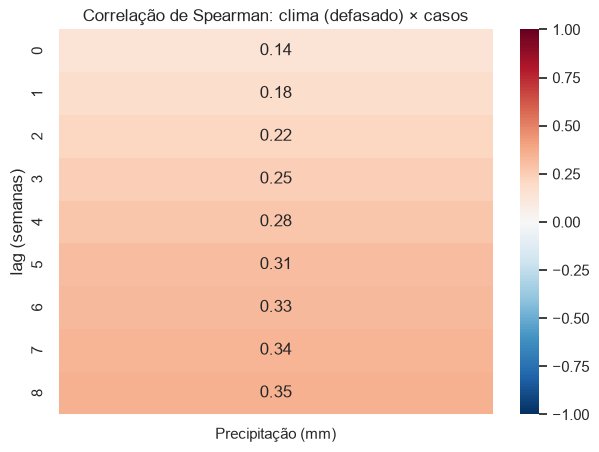

Melhor defasagem por variável (maior |correlação|):
  • Precipitação (mm): lag = 8 sem. (rho = +0.35)


In [9]:
# ---------- 8.1 Painel comparativo ----------
def fig_clima(d, titulo):
    fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.06,
                        row_heights=[0.5, 0.25, 0.25],
                        specs=[[{}], [{}], [{"secondary_y": True}]],
                        subplot_titles=("Casos × limiar", "Precipitação (mm)", "Temperatura (°C) e Umidade (%)"))
    fig.add_trace(go.Scatter(x=d["semana"], y=d["casos"], name="Casos", line=dict(color="#1f77b4")), row=1, col=1)
    fig.add_trace(go.Scatter(x=d["semana"], y=d["limiar"], name="Limiar", line=dict(color="#ff7f0e", dash="dash")), row=1, col=1)
    a = d[d["anomalia"]]
    fig.add_trace(go.Scatter(x=a["semana"], y=a["casos"], name="Anomalia", mode="markers",
                             marker=dict(color="red", size=8)), row=1, col=1)
    if "precip" in d and d["precip"].notna().any():
        fig.add_trace(go.Bar(x=d["semana"], y=d["precip"], name="Precipitação", marker_color="#4c9be8"), row=2, col=1)
    if "temp" in d and d["temp"].notna().any():
        fig.add_trace(go.Scatter(x=d["semana"], y=d["temp"], name="Temperatura", line=dict(color="#d62728")),
                      row=3, col=1, secondary_y=False)
    if "umid" in d and d["umid"].notna().any():
        fig.add_trace(go.Scatter(x=d["semana"], y=d["umid"], name="Umidade", line=dict(color="#2ca02c", dash="dot")),
                      row=3, col=1, secondary_y=True)
    fig.update_layout(title=titulo, height=800, template="plotly_white", hovermode="x unified",
                      legend=dict(orientation="h", y=-0.1))
    return fig

# Brasil (clima nacional)
fig_clima(det_br, "Brasil — casos × clima").show()
# Top 2 UFs
for uf in top_uf[:2]:
    fig_clima(det_uf[det_uf["uf"] == uf], f"UF {uf} — casos × clima").show()

# ---------- 8.2 Correlação defasada ----------
def zlog(s):
    x = np.log1p(s)                         # log reduz a assimetria dos picos
    return (x - x.mean()) / (x.std() if x.std() else 1)

corr_df = det_uf[det_uf["uf"] != "BR"].copy()
corr_df["casos_z"] = corr_df.groupby("uf")["casos"].transform(zlog)
for v in CLIMA:
    corr_df[v + "_z"] = corr_df.groupby("uf")[v].transform(lambda s: (s - s.mean()) / (s.std() if s.std() else 1))

linhas = []
for lag in range(LAG_MAX + 1):
    linha = {"lag (semanas)": lag}
    for v in CLIMA:
        x = corr_df.groupby("uf")[v + "_z"].shift(lag)          # clima de `lag` semanas atrás
        linha[nomes_clima[v]] = pd.concat([corr_df["casos_z"], x], axis=1).corr(method="spearman").iloc[0, 1]
    linhas.append(linha)
tab_corr = pd.DataFrame(linhas).set_index("lag (semanas)")

plt.figure(figsize=(7, 5))
sns.heatmap(tab_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlação de Spearman: clima (defasado) × casos")
plt.show()

print("Melhor defasagem por variável (maior |correlação|):")
for col in tab_corr.columns:
    lag_otimo = tab_corr[col].abs().idxmax()
    print(f"  • {col}: lag = {lag_otimo} sem. (rho = {tab_corr.loc[lag_otimo, col]:+.2f})")

## Célula 9 — Índice de risco por localidade
Combina três sinais das últimas `SEMANAS_RECENTES` semanas (cada um convertido em ranking percentual entre as localidades):
- **Crescimento** dos casos vs. as `SEMANAS_RECENTES` semanas anteriores (35%)
- **Volume** de casos recente (30%)
- **Persistência** de semanas anômalas nas últimas `2 × SEMANAS_RECENTES` semanas (35%)

> Como não temos população, o índice é um **risco relativo** (comparação entre localidades), não uma incidência por 100 mil hab. Se quiser, junte a população do IBGE e troque o volume por incidência.

In [10]:
def calcular_risco(det, grupo, n=SEMANAS_RECENTES):
    ult = det["semana"].max()
    ini_rec = ult - pd.Timedelta(weeks=n - 1)
    ini_ant = ini_rec - pd.Timedelta(weeks=n)
    rec = det[det["semana"] >= ini_rec]
    ant = det[(det["semana"] >= ini_ant) & (det["semana"] < ini_rec)]

    r = rec.groupby(grupo).agg(casos_recentes=("casos", "sum"),
                               z_max=("zscore", "max")).reset_index()
    a = ant.groupby(grupo).agg(casos_anteriores=("casos", "sum")).reset_index()
    # Persistência: anomalias nas últimas 2n semanas (um surto longo "contamina" a média móvel
    # e deixa de ser anômalo depois de algumas semanas; a janela maior evita perder esse sinal)
    ini_pers = ult - pd.Timedelta(weeks=2 * n - 1)
    p = (det[det["semana"] >= ini_pers].groupby(grupo)["anomalia"].sum()
         .rename("semanas_anomalas").reset_index())
    r = r.merge(a, on=grupo, how="left").merge(p, on=grupo, how="left")
    r = r.fillna({"casos_anteriores": 0, "z_max": 0, "semanas_anomalas": 0})
    r["z_max"] = r["z_max"].replace([np.inf, -np.inf], 0)
    r["crescimento_pct"] = (r["casos_recentes"] - r["casos_anteriores"]) / r["casos_anteriores"].clip(lower=1) * 100

    cresc = r["crescimento_pct"].clip(-100, 500)
    r["score_risco"] = 100 * (0.35 * cresc.rank(pct=True)
                              + 0.30 * r["casos_recentes"].rank(pct=True)
                              + 0.35 * (r["semanas_anomalas"] / (2 * n)).clip(upper=1))
    r["nivel"] = pd.cut(r["score_risco"], [-1, 25, 50, 75, 101],
                        labels=["Baixo", "Moderado", "Alto", "Crítico"]).astype(str)
    r.loc[r["casos_recentes"] < MIN_CASOS, "nivel"] = "Baixo"   # volume irrelevante nunca vira alerta
    return r.sort_values("score_risco", ascending=False).reset_index(drop=True)

risco_loc = calcular_risco(det_loc, chaves_loc)
risco_uf  = calcular_risco(det_uf[det_uf["uf"] != "BR"], ["uf"]) if (det_uf["uf"] != "BR").any() else None

print(f"Semana de referência: {det_loc['semana'].max():%d/%m/%Y}")
print("\nTop 15 localidades por risco:")
display(risco_loc.head(15))
print("Distribuição dos níveis:")
display(risco_loc["nivel"].value_counts().reindex(["Crítico", "Alto", "Moderado", "Baixo"]).fillna(0).astype(int).to_frame("localidades"))

Semana de referência: 22/06/2026

Top 15 localidades por risco:


,uf,municipio,casos_recentes,z_max,casos_anteriores,semanas_anomalas,crescimento_pct,score_risco,nivel
0,ES,320240,155.00,-0.35,0.00,1,"15,500.00",69.37,Alto
1,GO,522185,2.00,"234,576.64",0.00,0,200.00,64.96,Baixo
2,MT,510790,2.00,2.47,0.00,0,200.00,64.96,Baixo
3,MG,314480,2.00,5.30,1.00,0,100.00,64.84,Baixo
4,GO,520140,3.00,0.35,2.00,0,50.00,64.74,Baixo
5,DF,530010,1.00,"41,799.70",0.00,0,100.00,64.72,Baixo
6,ES,320530,1.00,"120,089.06",0.00,0,100.00,64.72,Baixo
7,AL,270030,1.00,-0.35,0.00,0,100.00,64.72,Baixo
8,CE,230680,1.00,-0.35,0.00,0,100.00,64.72,Baixo
9,MG,314800,1.00,"204,477.23",0.00,0,100.00,64.72,Baixo


Distribuição dos níveis:


,localidades
nivel,
Crítico,0
Alto,1
Moderado,0
Baixo,4822


## Célula 10 — Mapa interativo de risco atual
- Se você informar `COORD_MUN_CSV` (colunas `codigo`, `lat`, `lon`), o mapa mostra **municípios**.
- Caso contrário, mostra o risco por **UF** (centroide), que funciona sem arquivo extra.

In [11]:
CORES_RISCO = "YlOrRd"

def mapa_bolhas(df, nome_col, titulo):
    d = df.dropna(subset=["lat", "lon"]).copy()
    d["tamanho"] = d["casos_recentes"].clip(lower=1)
    fig = px.scatter_geo(d, lat="lat", lon="lon", size="tamanho", color="score_risco",
                         color_continuous_scale=CORES_RISCO, range_color=(0, 100),
                         hover_name=nome_col,
                         hover_data={"lat": False, "lon": False, "tamanho": False, "nivel": True,
                                     "casos_recentes": True, "crescimento_pct": ":.0f",
                                     "semanas_anomalas": True, "score_risco": ":.0f"},
                         size_max=45, title=titulo, scope="south america")
    fig.update_geos(fitbounds="locations", showcountries=True, showsubunits=True,
                    countrycolor="gray", subunitcolor="lightgray", showland=True, landcolor="#f4f4f4")
    fig.update_layout(height=650, coloraxis_colorbar=dict(title="Risco"))
    return fig

mapa_feito = False

# (a) Mapa de municípios, se houver arquivo de coordenadas
if COORD_MUN_CSV and TEM_MUN:
    coords = ler_csv(COORD_MUN_CSV)
    coords["chave"] = coords["codigo"].astype(str).str[:6]
    m = risco_loc.copy()
    m["chave"] = m["municipio"].astype(str).str[:6]
    m = m.merge(coords[["chave", "lat", "lon"]], on="chave", how="left")
    mapa_bolhas(m.head(300), "municipio", "Risco epidemiológico atual — municípios (top 300)").show()
    mapa_feito = True

# (b) Mapa por UF (centroide)
if risco_uf is not None:
    mu = risco_uf.copy()
    mu["lat"] = mu["uf"].map(lambda u: UF_COORD.get(u, (np.nan, np.nan))[0])
    mu["lon"] = mu["uf"].map(lambda u: UF_COORD.get(u, (np.nan, np.nan))[1])
    if mu[["lat", "lon"]].notna().all(axis=1).any():
        mapa_bolhas(mu, "uf", "Risco epidemiológico atual — por UF").show()
        mapa_feito = True

# (c) Fallback: ranking em barras
if not mapa_feito:
    print("Sem coordenadas disponíveis — exibindo ranking em barras.")
    top = risco_loc.head(20)
    nome_y = chaves_loc[-1]
    px.bar(top.iloc[::-1], x="score_risco", y=nome_y, color="nivel", orientation="h",
           title="Top 20 localidades por risco", labels={"score_risco": "Score de risco"}).show()

## Célula 11 — Alerta de Tendência automatizado
Lê a semana mais recente, compara com as semanas anteriores e gera um texto pronto para o painel (também salvo em arquivo).

**Regra do semáforo (nacional):**
- 🔴 **VERMELHO**: ≥ 2 semanas anômalas nas últimas 8 **e** crescimento > 25% (4 semanas vs. 4 anteriores)
- 🟡 **AMARELO**: pelo menos 1 semana anômala **ou** crescimento > 25%
- 🟢 **VERDE**: demais casos

In [12]:
def gerar_alerta():
    d = det_br.sort_values("semana").reset_index(drop=True)
    n = SEMANAS_RECENTES
    ult = d["semana"].max()
    rec, ant = d.tail(n), d.iloc[-2 * n:-n]
    casos_rec, casos_ant = rec["casos"].sum(), ant["casos"].sum()
    cresc = (casos_rec - casos_ant) / max(casos_ant, 1) * 100
    sem_anom = int(d.tail(2 * n)["anomalia"].sum())          # anomalias nas últimas 2n semanas
    ultima_sem = d.iloc[-1]

    if sem_anom >= 2 and cresc > 25:
        semaforo, emoji, cor = "VERMELHO — possível surto em andamento", "🔴", "#d62728"
    elif sem_anom >= 1 or cresc > 25:
        semaforo, emoji, cor = "AMARELO — atenção: crescimento acima do esperado", "🟡", "#e6a700"
    else:
        semaforo, emoji, cor = "VERDE — situação dentro do esperado", "🟢", "#2ca02c"
    tendencia = "ALTA ↗" if cresc > 25 else ("QUEDA ↘" if cresc < -25 else "ESTÁVEL →")

    linhas = [
        f"{emoji} ALERTA DE TENDÊNCIA — DENGUE | Semana de referência: {ult:%d/%m/%Y}",
        f"Status nacional: {semaforo}",
        "",
        f"• Casos na última semana: {int(ultima_sem['casos']):,} "
        f"(limiar esperado: {ultima_sem['limiar']:,.0f})" if pd.notna(ultima_sem["limiar"]) else
        f"• Casos na última semana: {int(ultima_sem['casos']):,}",
        f"• Últimas {n} semanas: {int(casos_rec):,} casos vs. {int(casos_ant):,} nas {n} anteriores "
        f"→ tendência {tendencia} ({cresc:+.0f}%)",
        f"• Semanas anômalas nas últimas {2 * n}: {sem_anom}",
    ]

    # Localidades em anomalia na semana mais recente
    ult_loc = det_loc[det_loc["semana"] == det_loc["semana"].max()]
    n_anom, n_tot = int(ult_loc["anomalia"].sum()), len(ult_loc)
    linhas.append(f"• {NOME_LOC.capitalize()}s em anomalia na última semana: {n_anom} de {n_tot} monitorados ({n_anom / max(n_tot, 1):.0%})")

    # Localidades mais críticas
    linhas += ["", f"Localidades de maior risco ({NOME_LOC}):"]
    for i, r in risco_loc.head(5).iterrows():
        rotulo = " / ".join(str(r[c]) for c in chaves_loc)
        linhas.append(f"  {i + 1}. {rotulo} — nível {r['nivel']} | score {r['score_risco']:.0f} | "
                      f"{int(r['casos_recentes'])} casos ({r['crescimento_pct']:+.0f}%) | "
                      f"{int(r['semanas_anomalas'])} sem. anômalas (últ. {2 * n})")

    # Clima recente vs. histórico
    linhas += ["", "Condições climáticas (média das últimas semanas vs. média histórica):"]
    for v in CLIMA:
        if d[v].notna().sum() > n:
            r_, h_ = d[v].tail(n).mean(), d[v].mean()
            dif = (r_ - h_) / abs(h_) * 100 if h_ else np.nan
            linhas.append(f"  • {nomes_clima[v]}: {r_:.1f} vs. {h_:.1f} histórico ({dif:+.0f}%)")
    prec = tab_corr["Precipitação (mm)"] if "Precipitação (mm)" in tab_corr else None
    if prec is not None:
        lag_p = prec.abs().idxmax()
        linhas.append(f"  → Chuva costuma anteceder os casos em ~{lag_p} semana(s) (rho = {prec[lag_p]:+.2f}); "
                      f"monitore a chuva das últimas semanas para antecipar o próximo ciclo.")

    linhas += ["", "Obs.: alerta estatístico exploratório (média móvel + desvios); não substitui a vigilância oficial."]
    return "\n".join(linhas), cor

texto_alerta, cor_alerta = gerar_alerta()
print(texto_alerta)
display(HTML(f"<div style='border-left:8px solid {cor_alerta};padding:12px 16px;background:#fafafa;"
             f"font-family:monospace;white-space:pre-wrap'>{texto_alerta}</div>"))

# ---- Exporta resultados (CSV + texto) para a pasta processed ----
PASTA_SAIDA = CAM_SINAN.parent
risco_loc.to_csv(PASTA_SAIDA / "risco_localidades.csv", index=False, encoding="utf-8-sig")
det_loc.to_csv(PASTA_SAIDA / "serie_anomalias_localidades.csv", index=False, encoding="utf-8-sig")
(PASTA_SAIDA / "alerta_tendencia.txt").write_text(texto_alerta, encoding="utf-8")
print(f"\nArquivos salvos em: {PASTA_SAIDA}")

🔴 ALERTA DE TENDÊNCIA — DENGUE | Semana de referência: 22/06/2026
Status nacional: VERMELHO — possível surto em andamento

• Casos na última semana: 8 (limiar esperado: 144)
• Últimas 4 semanas: 203 casos vs. 135 nas 4 anteriores → tendência ALTA ↗ (+50%)
• Semanas anômalas nas últimas 8: 2
• Municipios em anomalia na última semana: 0 de 4823 monitorados (0%)

Localidades de maior risco (municipio):
  1. ES / 320240 — nível Alto | score 69 | 155 casos (+15500%) | 1 sem. anômalas (últ. 8)
  2. GO / 522185 — nível Baixo | score 65 | 2 casos (+200%) | 0 sem. anômalas (últ. 8)
  3. MT / 510790 — nível Baixo | score 65 | 2 casos (+200%) | 0 sem. anômalas (últ. 8)
  4. MG / 314480 — nível Baixo | score 65 | 2 casos (+100%) | 0 sem. anômalas (últ. 8)
  5. GO / 520140 — nível Baixo | score 65 | 3 casos (+50%) | 0 sem. anômalas (últ. 8)

Condições climáticas (média das últimas semanas vs. média histórica):
  • Precipitação (mm): nan vs. 17.6 histórico (+nan%)
  → Chuva costuma anteceder os caso


Arquivos salvos em: C:\Users\Usuário\Desktop\Dengue_Alerta\data\processed
